In [16]:
%load_ext autoreload
%autoreload 2


from index.inverted_index import Index
from index.documents import load_dataset, tokenizer

msmarco = load_dataset("msmarco-passage/dev/judged")

NUM_DOCS = 100000
K = 10

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Create the inverting index using shuffle

In [17]:
import random
from index.ordered_dataset import OrderedDataset

docs = []
for i, doc in enumerate(msmarco.docs_iter()):
    docs.append(doc)
    if i == NUM_DOCS - 1:
        break

order = list(range(1, NUM_DOCS + 1))
random.shuffle(order)

random_dataset = OrderedDataset(docs, order)

# for doc in random_dataset.docs_iter():
#     print(doc)


unordered_index = Index()
unordered_index.build_index(random_dataset, tokenizer, max_num_docs=NUM_DOCS)

Processing:   99.0% [99000/100000] | Current docid: 99000               

## Creating the tf-idf matrix

In [18]:
from index.reorder_utils import create_sparse_tf_idf_matrix
import pandas as pd

tf_idf_matrix, doc_ids, terms = create_sparse_tf_idf_matrix(unordered_index)
df = pd.DataFrame.sparse.from_spmatrix(tf_idf_matrix, index=doc_ids, columns=terms)


## Kmeans

In [20]:
from index.reorder_utils import k_medoids, reorder_documents_by_tsp, tsp_path
from time import perf_counter
K = [10,20,50,60,80,100,120,150,170,200]

time_unordered = []
time_ordered = []
results_unordered = []
results_ordered = []

for k in K:
    print(f"using {k} total clusters")
    medoids, medoids_id, cluster_to_docs = k_medoids(df, k)
    from index.reorder_utils import calculate_distance_matrix
    dist_matrix = calculate_distance_matrix(medoids, method="jaccard")
    tsp_path_ = tsp_path(dist_matrix)
    new_order = reorder_documents_by_tsp(tsp_path_,cluster_to_docs, medoids_id)
    ordered_dataset = OrderedDataset(docs, new_order)

    reordered_inverted_index = Index()
    reordered_inverted_index.clear_index()
    reordered_inverted_index.build_index(
        ordered_dataset,
        tokenizer,
        max_num_docs=-1, #! -1 since reordered docs are already limited to 10001 in the original index
        d_gap=True
    )

    unordered_index = Index()
    unordered_index.clear_index()
    unordered_index.build_index(random_dataset,tokenizer,max_num_docs=-1,d_gap=True)
    start = perf_counter()
    unordered_index.compress_index("gamma")
    end = abs(perf_counter() - start)
    results_unordered.append(unordered_index.get_approx_size())
    time_unordered.append(end)

    start = perf_counter()
    reordered_inverted_index.compress_index("gamma")
    end = abs(perf_counter() - start)
    results_ordered.append(reordered_inverted_index.get_approx_size())
    time_ordered.append(end)



using 10 total clusters
Processing:    1.0% [1000/100000] | Current docid: 1000                

c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Processing:   99.0% [99000/100000] | Current docid: 99000               using 20 total clusters


c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Processing:   99.0% [99000/100000] | Current docid: 99000               using 50 total clusters


...

Processing:   99.0% [99000/100000] | Current docid: 99000               using 170 total clusters


c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Processing:   99.0% [99000/100000] | Current docid: 99000               using 200 total clusters


c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Processing:   99.0% [99000/100000] | Current docid: 99000               

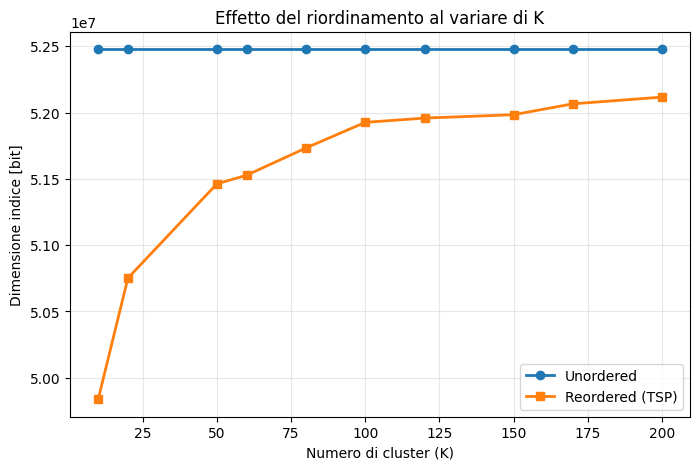

In [21]:
import matplotlib.pyplot as plt

unordered_total = [r["total_bits"] for r in results_unordered]
ordered_total = [r["total_bits"] for r in results_ordered]

plt.figure(figsize=(8,5))

plt.plot(K, unordered_total, marker='o', linewidth=2, label="Unordered")
plt.plot(K, ordered_total, marker='s', linewidth=2, label="Reordered (TSP)")

plt.xlabel("Numero di cluster (K)")
plt.ylabel("Dimensione indice [bit]")
plt.title("Effetto del riordinamento al variare di K")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

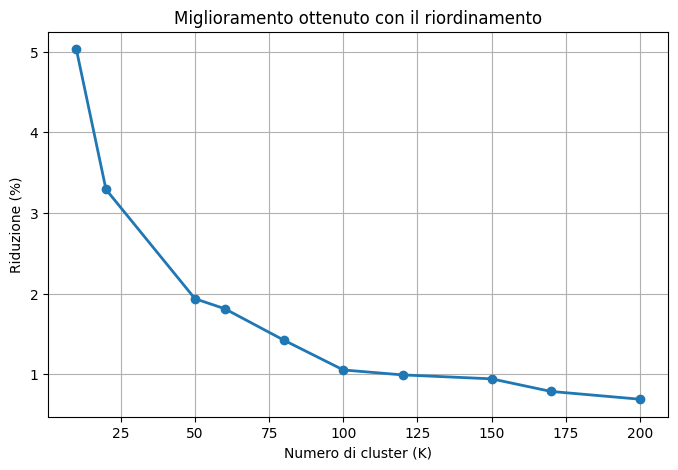

In [22]:
improvement = [
    (u["total_bits"] - o["total_bits"]) / u["total_bits"] * 100
    for u, o in zip(results_unordered, results_ordered)
]

plt.figure(figsize=(8,5))

plt.plot(K, improvement, marker='o', linewidth=2)

plt.xlabel("Numero di cluster (K)")
plt.ylabel("Riduzione (%)")
plt.title("Miglioramento ottenuto con il riordinamento")
plt.grid(True)

plt.show()

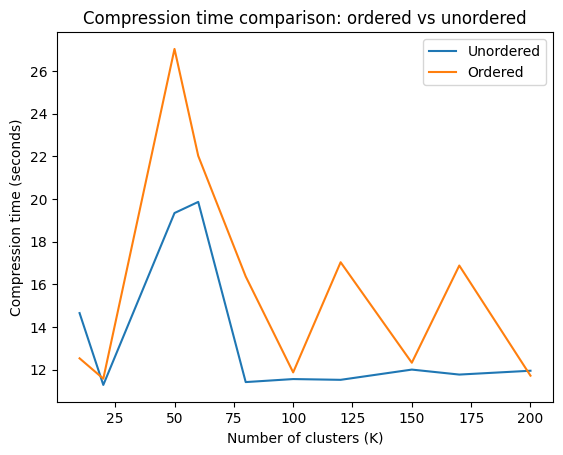

In [23]:
from matplotlib import pyplot as plt

plt.figure()

plt.plot(K, time_unordered, label="Unordered")
plt.plot(K, time_ordered, label="Ordered")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Compression time (seconds)")
plt.title("Compression time comparison: ordered vs unordered")
plt.legend()

plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

term = [r["term_bytes"] * 8 for r in results_ordered]  # converto in bit
doc = [r["doc_id_bits"] for r in results_ordered]
tf = [r["tf_bits"] for r in results_ordered]

means = [
    np.mean(term),
    np.mean(doc),
    np.mean(tf)
]

plt.bar(["Term", "Doc IDs", "TF"], means)
plt.ylabel("Bit medi")
plt.title("Dimensione media delle componenti")
plt.show()


## Create the distance matrix

In [35]:
from index.reorder_utils import calculate_distance_matrix
print(medoids)
dist_matrix = calculate_distance_matrix(medoids, method="jaccard")
 

[[0.         0.         0.01878068 ... 0.         0.         0.        ]
 [0.         0.         0.02190619 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.23687508 0.         0.        ]
 [0.07967107 0.07232065 0.02390739 ... 0.         0.         0.        ]]


c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


## TSP path

In [36]:
from index.reorder_utils import tsp_path

tsp_path = tsp_path(dist_matrix)

print(tsp_path)

[2, 1, 3, 5, 9, 6, 4, 7, 8, 0]


## Reorder

In [38]:
from index.reorder_utils import reorder_documents_by_tsp

new_order = reorder_documents_by_tsp(tsp_path,cluster_to_docs, medoids_id)
print(new_order)

[4, 29, 97, 102, 105, 142, 159, 179, 246, 249, 254, 268, 314, 319, 412, 431, 453, 488, 519, 541, 652, 722, 822, 972, 1005, 1044, 1058, 1064, 1141, 1156, 1180, 1268, 1286, 1291, 1324, 1349, 1403, 1408, 1421, 1424, 1431, 1479, 1529, 1535, 1555, 1570, 1653, 1741, 1770, 1786, 1928, 1929, 1976, 2021, 2089, 2096, 2154, 2165, 2176, 2346, 2396, 2456, 2489, 2493, 2538, 2547, 2571, 2608, 2627, 2639, 2665, 2715, 2739, 2854, 2858, 2860, 2928, 2929, 2969, 2981, 3026, 3081, 3086, 3129, 3138, 3255, 3300, 3338, 3362, 3364, 3372, 3418, 3445, 3481, 3518, 3567, 3601, 3604, 3642, 3685, 3696, 3710, 3771, 3805, 3808, 3871, 3873, 3874, 3951, 3966, 4089, 4136, 4224, 4298, 4306, 4329, 4345, 4406, 4408, 4453, 4569, 4649, 4656, 4707, 4734, 4778, 4799, 4809, 4842, 4856, 4868, 4905, 4995, 4997, 5027, 5073, 5116, 5126, 5166, 5176, 5244, 5257, 5271, 5416, 5441, 5461, 5469, 5551, 5570, 5594, 5702, 5727, 5732, 5757, 5771, 5785, 5877, 5896, 6015, 6019, 6043, 6181, 6186, 6220, 6312, 6466, 6472, 6530, 6595, 6673, 6749, 6

## Experiment

In [44]:

ordered_dataset = OrderedDataset(docs, new_order)

reordered_inverted_index = Index()
reordered_inverted_index.build_index(
    ordered_dataset,
    tokenizer,
    max_num_docs=-1, #! -1 since reordered docs are already limited to 10001 in the original index
    d_gap=True
)

stat_r = reordered_inverted_index.get_approx_size()


unordered_index = Index()
unordered_index.build_index(random_dataset,tokenizer,max_num_docs=-1,d_gap=True)
unordered_index.get_approx_size()



Processing:   90.0% [9000/10000] | Current docid: 9000                
=== Index Size Breakdown ===
Doc ID bits:  12,172,320
TF bits:      12,172,320
Total bits:   24,344,640
Total bytes:  3,043,080.00
Processing:   90.0% [9000/10000] | Current docid: 9000                
=== Index Size Breakdown ===
Doc ID bits:  12,172,320
TF bits:      12,172,320
Total bits:   24,344,640
Total bytes:  3,043,080.00


{'term_bytes': 0,
 'doc_id_bits': 12172320,
 'tf_bits': 12172320,
 'total_bits': 24344640,
 'total_bytes': 3043080.0}

## Compression Ordered by TSP

In [45]:
unordered_index.compress_index("gamma")
unordered_index.get_approx_size()

reordered_inverted_index.compress_index("gamma")
reordered_inverted_index.get_approx_size()








=== Index Size Breakdown ===
Doc ID bits:  4,394,453
TF bits:      583,087
Total bits:   4,977,540
Total bytes:  622,192.50

=== Index Size Breakdown ===
Doc ID bits:  4,221,537
TF bits:      583,087
Total bits:   4,804,624
Total bytes:  600,578.00


{'term_bytes': 0,
 'doc_id_bits': 4221537,
 'tf_bits': 583087,
 'total_bits': 4804624,
 'total_bytes': 600578.0}